# Benchmark contract v2 (2026-10-29)
The active cleaned estimator uses the closed mathematical lifetime grid 0.20+0.01k ns, k=0,...,60. Historical upstream curves below retain their original implementation provenance. The v2 Judge checks per-pixel first-harmonic collinearity, second-harmonic objective quality and projection, plus grid/support constraints; near-degenerate equivalent minima need not have matching lifetimes. The original NumPy half-open range unexpectedly contained 61 samples including 0.8 ns, which is now explicitly part of the physical prior. The v2 baseline is a fresh cleaned conditional estimate, never physical truth.

# NADH: observations to latent components
## 1. Problem
Recover **two component lifetimes and their bound intensity fraction per pixel**, rather than an apparent phase lifetime. We observe full measured breast-cancer-cell time histograms plus an independent fluorescein standard. There is **no biological GT**: original official-method arrays are an identified reproducibility reference. Interpreting a fitted lifetime as a unique binding state is an approximation.

## 2. Data
The author supplied prefiltered uint8 histograms with97delaybins over512x512pixels. Intensities are processed units, not raw Poisson counts. All data are retained; support is fixed by observed total>0. No output-based mask.

Full arrays (512, 512, 97) (512, 512, 97) observed pixels 92029


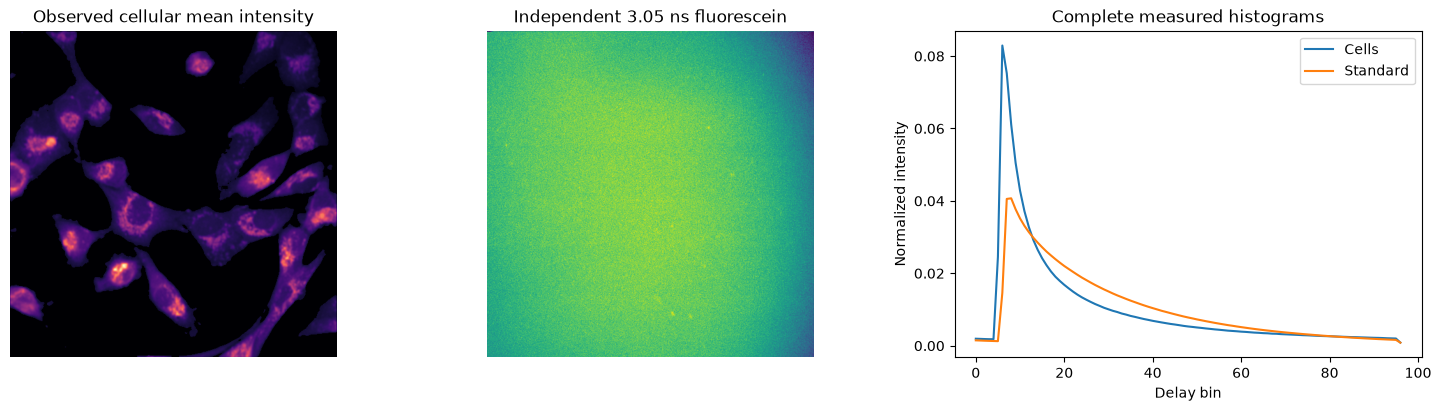

In [1]:
from pathlib import Path
import os,sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.physics_model import calibrated_phasors,mixture_phasors,OMEGA
from src.solvers import reconstruct,graphical_search
from src.visualization import image_grid,forward_residual
signal,calibration=load_data()
support=signal.sum(-1,dtype=np.float64)>0
print('Full arrays',signal.shape,calibration.shape,'observed pixels',int(support.sum()))
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
ax[0].imshow(signal.mean(-1),cmap='magma');ax[0].set_title('Observed cellular mean intensity');ax[0].set_axis_off()
ax[1].imshow(calibration.mean(-1),cmap='viridis');ax[1].set_title('Independent 3.05 ns fluorescein');ax[1].set_axis_off()
ax[2].plot(signal.sum((0,1))/signal.sum(),label='Cells');ax[2].plot(calibration.sum((0,1))/calibration.sum(),label='Standard');ax[2].set(xlabel='Delay bin',ylabel='Normalized intensity',title='Complete measured histograms');ax[2].legend()
plt.show()

## 3. Physics
For harmonic h and pixel p, calibrated moments obey

$$z_h(p)=\frac{1-f(p)}{1-\mathrm{i}h\omega\tau_f(p)}+\frac{f(p)}{1-\mathrm{i}h\omega\tau_b(p)}.$$

The angular frequency is omega=2 pi times0.08/ns; lifetimes tau-f and tau-b are ns; f is a **time-integrated intensity fraction**, not concentration or initial exponential amplitude. First and second harmonics supply four real observations for three unknowns. The moment is normalized positive-sine DFT; independent fluorescein corrects instrument rotation/modulation. Complex moments and residuals are dimensionless.

## 4. Method
The 2020 graphical two-component construction scans a fast-lifetime prior, draws the line through each candidate and the first-harmonic observation, intersects the universal semicircle to infer the slow endpoint, and minimizes the second-harmonic distance from the mapped endpoint line. The reported fraction is the second-harmonic projection. Under noise this is **not** a joint four-moment least-squares fit.

The official PhasorPy0.12 author-led open implementation is the oracle; this does not reproduce the historical closed SimFCS binary. The original single-harmonic comparison assumes0.4ns free lifetime and infers a common slow endpoint from the intensity-weighted cell centroid. That inferred endpoint stays a model estimate. Both methods below are freshly computed from full observations.

Fresh full reconstruction seconds: 3.115340600023046 Judge: pass
{
  "forward_rms": 0.03433711446607921,
  "grid_membership_max_ns": 1.887379141862766e-15,
  "first_harmonic_line_max": 3.7238012298709097e-16,
  "fraction_projection_max": 6.661338147750939e-16,
  "second_harmonic_objective_excess_max": 0.0
}
Single-harmonic inferred slow endpoint: 3.609263125042904 ns


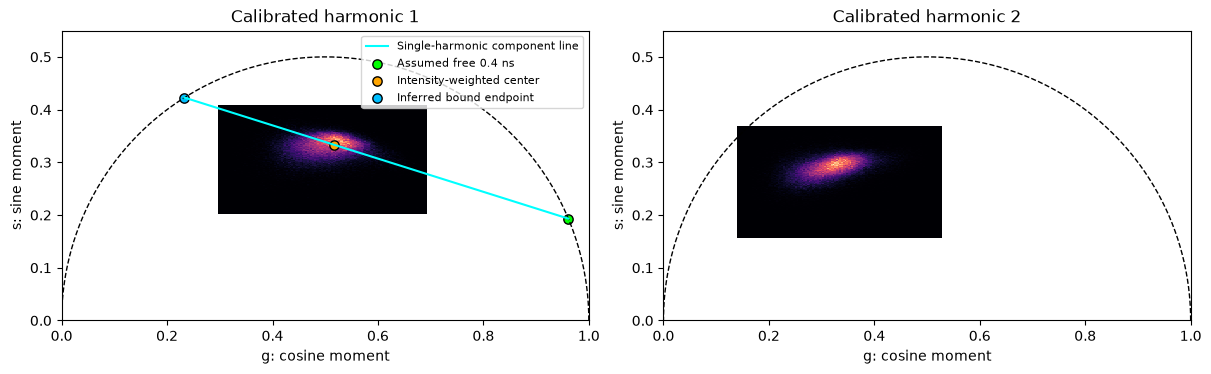

In [2]:
start=time.perf_counter()
fresh,details=reconstruct(signal,calibration)
seconds=time.perf_counter()-start
np.savez_compressed('output/reconstruction.npz',**fresh)
spec=importlib.util.spec_from_file_location('judge',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exitcode=judge.evaluate(ROOT/'output/reconstruction.npz')
print('Fresh full reconstruction seconds:',seconds,'Judge:',report['status'])
print(json.dumps(report['metrics'],indent=2));assert exitcode==0
original=dict(np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False))
mean=details['mean'];z=details['phasors'];tau=fresh['reconstruction'][0];bound=fresh['bound_fraction'][0]
print('Single-harmonic inferred slow endpoint:',details['single_bound_lifetime'],'ns')
fig,ax=plt.subplots(1,2,figsize=(12,5),layout='constrained')
circle=np.linspace(0,np.pi,300)
for h,a in enumerate(ax):
 a.hist2d(z[h].real[support],z[h].imag[support],bins=120,cmap='magma');a.plot(.5+.5*np.cos(circle),.5*np.sin(circle),'k--',lw=1);a.set(xlabel='g: cosine moment',ylabel='s: sine moment',title=f'Calibrated harmonic {h+1}',xlim=(0,1),ylim=(0,.55),aspect='equal')
a=1/(1-1j*OMEGA*.4);endpoint=1/(1-1j*OMEGA*details['single_bound_lifetime']);center=np.nansum(z[0]*mean)/mean[support].sum()
ax[0].plot([a.real,endpoint.real],[a.imag,endpoint.imag],color='cyan',label='Single-harmonic component line')
for point,label,color in [(a,'Assumed free 0.4 ns','lime'),(center,'Intensity-weighted center','orange'),(endpoint,'Inferred bound endpoint','deepskyblue')]:
 ax[0].scatter(point.real,point.imag,c=color,s=45,edgecolor='black',label=label)
ax[0].legend(fontsize=8,loc='upper right')
plt.show()

## 5. Results and experiments
### Latent maps and the original comparison
Every fresh map below was computed in the preceding cell. Transparent pixels are unobserved background. Slow lifetime uses a6ns display limit matching the original comparison; the uncensored distribution and tail count are shown next. The official tutorial itself notes disagreement of single-harmonic fractions with the historical2025Fig6c. That data paper distinguishes distance from a free endpoint, normalized intensity fraction, and exponential amplitude fraction. We make no claim of reproducing that figure's numerical values.

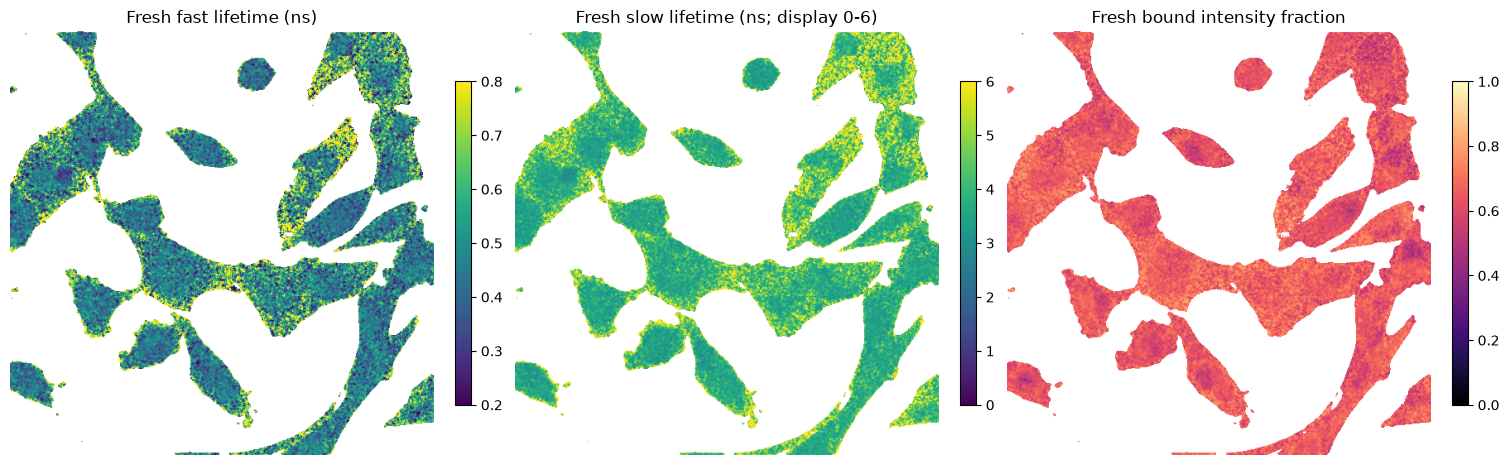

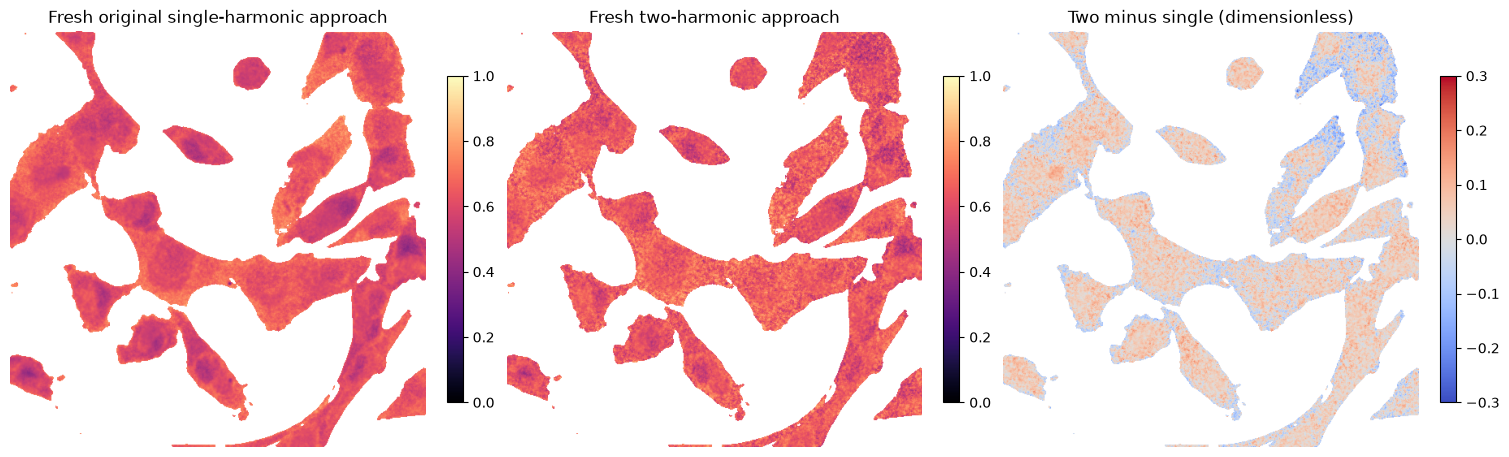

Slow >6ns: 6142 of 92029
Fast prior endpoint populations: 1127 5442


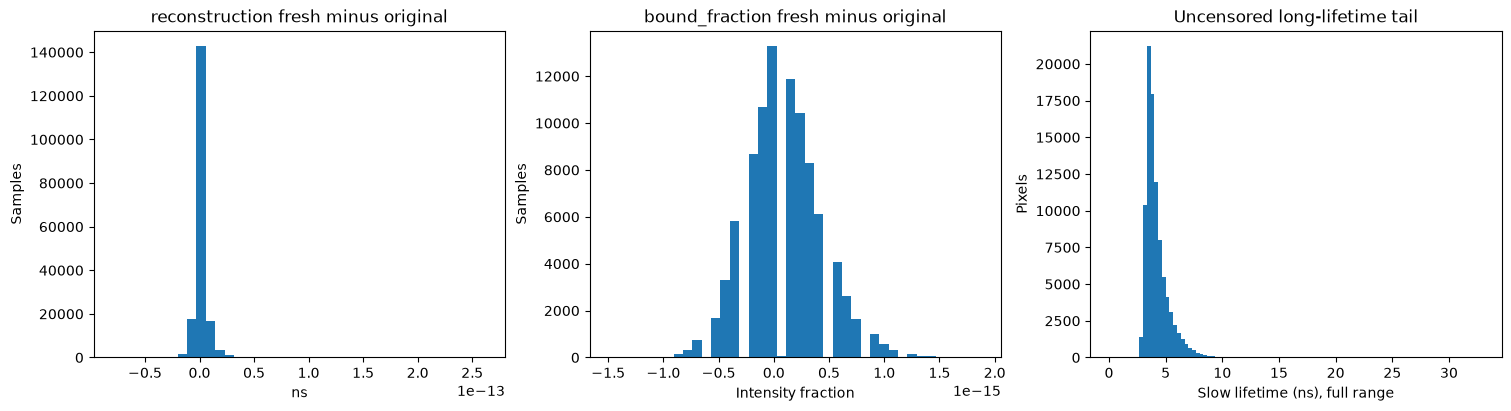

In [3]:
display=lambda a:np.where(support,a,np.nan)
image_grid([display(tau[0]),display(tau[1]),display(bound)],['Fresh fast lifetime (ns)','Fresh slow lifetime (ns; display 0-6)','Fresh bound intensity fraction'],[(.2,.8),(0,6),(0,1)],['viridis','viridis','magma']);plt.show()
image_grid([display(details['single_fraction']),display(bound),display(bound-details['single_fraction'])],['Fresh original single-harmonic approach','Fresh two-harmonic approach','Two minus single (dimensionless)'],[(0,1),(0,1),(-.3,.3)],['magma','magma','coolwarm']);plt.show()
fig,ax=plt.subplots(1,3,figsize=(15,4),layout='constrained')
for i,key in enumerate(['reconstruction','bound_fraction']):
 a=fresh[key];b=original[key];mask=np.broadcast_to(support,a.shape);delta=a[mask]-b[mask]
 ax[i].hist(delta,bins=40);ax[i].set(title=key+' fresh minus original',xlabel='ns' if i==0 else 'Intensity fraction',ylabel='Samples')
ax[2].hist(tau[1][support],bins=np.linspace(0,33,100));ax[2].set(xlabel='Slow lifetime (ns), full range',ylabel='Pixels',title='Uncensored long-lifetime tail')
print('Slow >6ns:',int((tau[1][support]>6).sum()),'of',int(support.sum()))
print('Fast prior endpoint populations:',int(np.isclose(tau[0][support],.2).sum()),int(np.isclose(tau[0][support],.8).sum()))
plt.show()

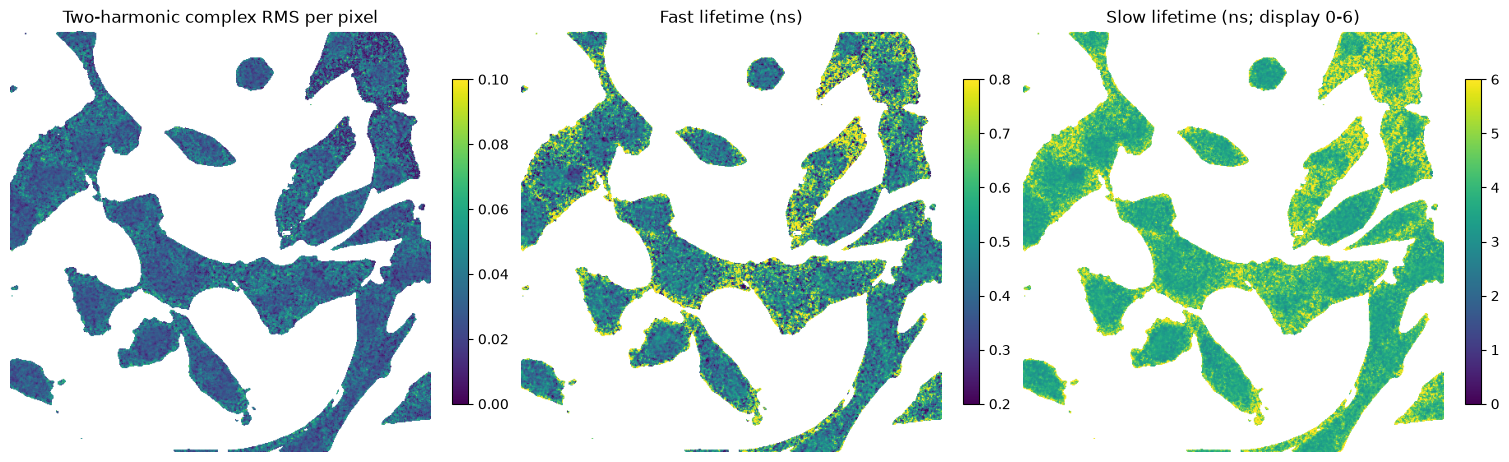

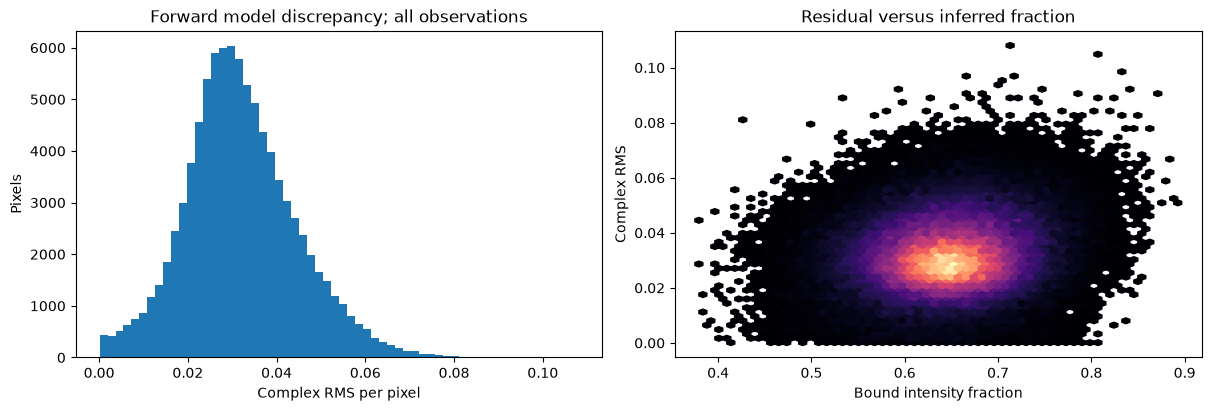

Forward RMS: 0.03433711446607921 95th percentile: 0.05416358553603743


In [4]:
residual=forward_residual(fresh,z,support)
image_grid([residual,display(tau[0]),display(tau[1])],['Two-harmonic complex RMS per pixel','Fast lifetime (ns)','Slow lifetime (ns; display 0-6)'],[(0,.1),(.2,.8),(0,6)]);plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
ax[0].hist(residual[support],bins=60);ax[0].set(xlabel='Complex RMS per pixel',ylabel='Pixels',title='Forward model discrepancy; all observations')
ax[1].hexbin(bound[support],residual[support],gridsize=60,mincnt=1,cmap='magma');ax[1].set(xlabel='Bound intensity fraction',ylabel='Complex RMS',title='Residual versus inferred fraction')
plt.show()
print('Forward RMS:',np.sqrt(np.mean(residual[support]**2)),'95th percentile:',np.quantile(residual[support],.95))

[
  {
    "method": "Original two-harmonic",
    "mean_bound_fraction": 0.6463494650087276,
    "twoharmonic_forward_rms": 0.03433711446607914
  },
  {
    "method": "Fresh two-harmonic",
    "mean_bound_fraction": 0.6463494650087277,
    "twoharmonic_forward_rms": 0.03433711446607921
  },
  {
    "method": "Original single-harmonic",
    "mean_bound_fraction": 0.6246786797140821,
    "twoharmonic_forward_rms": 0.04227513926573944
  },
  {
    "method": "Fresh single-harmonic",
    "mean_bound_fraction": 0.6246786797140821,
    "twoharmonic_forward_rms": 0.04227513926573945
  }
]


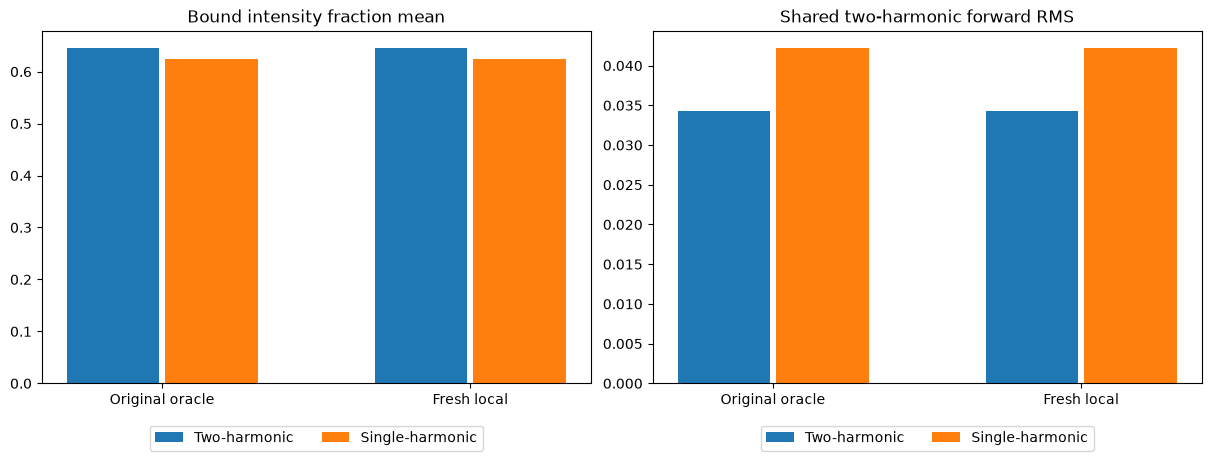

In [5]:
# Paired original/fresh quantitative comparisons for both retained methods.
rows=[]
orig_tau=original['reconstruction'][0];orig_f=original['bound_fraction'][0]
for label,t,f in [('Original two-harmonic',orig_tau,orig_f),('Fresh two-harmonic',tau,bound),('Original single-harmonic',np.stack([np.full_like(bound,.4),np.full_like(bound,details['single_bound_lifetime'])]),original['single_harmonic_fraction'][0]),('Fresh single-harmonic',np.stack([np.full_like(bound,.4),np.full_like(bound,details['single_bound_lifetime'])]),details['single_fraction'])]:
 model=(1-f)[None]/(1-1j*OMEGA*np.arange(1,3)[:,None,None]*t[0])+f[None]/(1-1j*OMEGA*np.arange(1,3)[:,None,None]*t[1])
 rows.append(dict(method=label,mean_bound_fraction=float(f[support].mean()),twoharmonic_forward_rms=float(np.sqrt(np.mean(abs(model[:,support]-z[:,support])**2)))))
print(json.dumps(rows,indent=2))
fig,ax=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for a,key,title in zip(ax,['mean_bound_fraction','twoharmonic_forward_rms'],['Bound intensity fraction mean','Shared two-harmonic forward RMS']):
 for j,indices in enumerate([[0,1],[2,3]]):
  a.bar(np.array([0,1])+j*.32,[rows[k][key] for k in indices],width=.3,label=['Two-harmonic','Single-harmonic'][j])
 a.set_xticks([.16,1.16],['Original oracle','Fresh local']);a.set_title(title);a.legend(loc='upper center',bbox_to_anchor=(.5,-.10),ncol=2)
plt.show()


### Sensitivity: prior, discretization and calibration
These fresh comparisons intentionally vary the official benchmark settings and never replace its output. Calibrated phasors are reused only as preprocessing; each inverse is computed again. Omission of calibration is a physical diagnostic using the same measured histograms. NaN or out-of-domain solutions in this ablation are explicitly counted, not converted into successful estimates.

[
  {
    "experiment": "Coarse grid .02ns",
    "valid_pixels": 92029,
    "fraction_rms_change": 0.002387329898294673,
    "fast_rms_change_ns": 0.006835286552050246
  },
  {
    "experiment": "Wider fast prior .1-1ns",
    "valid_pixels": 92029,
    "fraction_rms_change": 0.013882071006676605,
    "fast_rms_change_ns": 0.03233738153856408
  },
  {
    "experiment": "No standard correction",
    "valid_pixels": 1,
    "fraction_rms_change": 0.1320952371734393,
    "fast_rms_change_ns": 0.6000000000000026
  }
]


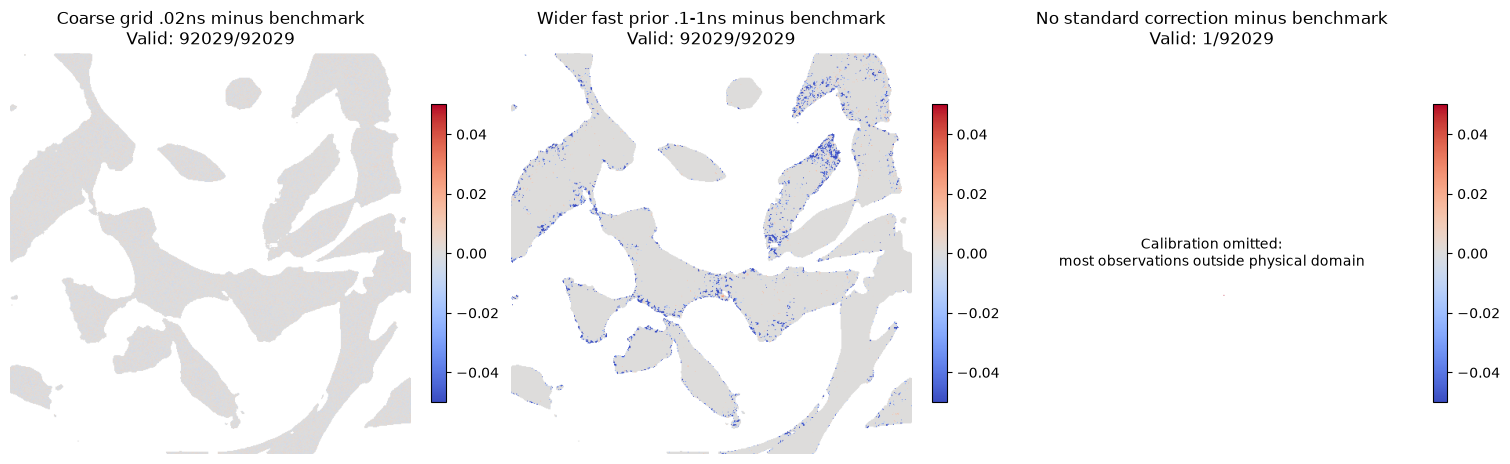

In [6]:
experiments={}
for label,grid in [('Coarse grid .02ns',(.2,.8,.02)),('Wider fast prior .1-1ns',(.1,1.,.01))]:
 t,f=graphical_search(z,grid);valid=support&np.isfinite(t).all(0)&np.isfinite(f).all(0)
 experiments[label]=(t,f[1],valid)
ft=np.fft.rfft(signal,axis=-1)[...,[1,2]].conj();total=signal.sum(-1,dtype=np.float64)
raw=np.moveaxis(ft,-1,0)/np.where(total>0,total,1)[None];raw[:,~support]=np.nan
t,f=graphical_search(raw);valid=support&np.isfinite(t).all(0)&np.isfinite(f).all(0);experiments['No standard correction']=(t,f[1],valid)
fig,ax=plt.subplots(1,3,figsize=(15,4.6),layout='constrained')
summary=[]
for a,(label,(t,f,valid)) in zip(ax,experiments.items()):
 im=a.imshow(np.where(valid,f-bound,np.nan),vmin=-.05,vmax=.05,cmap='coolwarm');a.set_title(label+' minus benchmark\nValid: '+str(int(valid.sum()))+'/'+str(int(support.sum())));a.set_axis_off();fig.colorbar(im,ax=a,shrink=.7)
 if valid.sum()<10:a.text(.5,.5,'Calibration omitted:\nmost observations outside physical domain',transform=a.transAxes,ha='center',va='center',fontsize=10)
 summary.append(dict(experiment=label,valid_pixels=int(valid.sum()),fraction_rms_change=float(np.sqrt(np.mean((f[valid]-bound[valid])**2))),fast_rms_change_ns=float(np.sqrt(np.mean((t[0,valid]-tau[0,valid])**2)))))
print(json.dumps(summary,indent=2));plt.show()

## 6. Conclusion
The full measured images support a reproducible two-component inverse computation, and the extracted implementation matches independently frozen official outputs for all three unknown fields. There is no direct lifetime or binding-fraction GT for these cells. A nonzero two-harmonic forward residual, fast-prior boundary populations, long slow-lifetime tails and sensitivity to calibration/prior quantify the limits of the biexponential interpretation. Good reference parity does not validate the inferred molecular identity or metabolic flux. The single-harmonic comparison retains the original tutorial's scientific alternative and its acknowledged historical-figure discrepancy.

Sources: 2020 theory DOI10.1021/acs.jpcb.0c06946; 2025 real-data protocol DOI10.1117/1.JBO.30.S2.S23901; original open implementation PhasorPy0.12, exact revision and stage mapping in hidden validation. Data copyright2024JanetSorrells CC BY4.0; local adapted algorithm MIT.